# Passo 1 — Escolha do candle (Random Forest, previsão T+1 do WIN)

**Pergunta:** qual tamanho de candle (1, 5, 15, 30 ou 60 min) dá a melhor base para prever o retorno do próximo candle?

O passo tem duas partes:

1. **Análise de dados (sem modelo, só dados até 31/12/2023).** Quanto o preço anda em cada candle frente ao custo, se existe memória de um candle para o próximo (ρ₁) e quanta informação as features básicas carregam.
2. **Modelo (seleção em 2024).** Um RF fixo e simples treinado em cada candle, com tudo o mais igual: janela de 12 meses, re-treino trimestral e as mesmas features.

| Fixo neste passo | Valor |
|---|---|
| Alvo | $r_{t+1} = 100 \cdot \ln(C_{t+1}/C_t)$, só dentro do mesmo pregão |
| Janela de treino | 12 meses (revista no passo 3) |
| Re-treino | trimestral, em 2024 |
| Features | básicas: `ret_0`, `ret_1`, `ret_2`, `vol_20`, `hora` (revistas no passo 2) |
| RF | 200 árvores, profundidade 5, 1% do treino por folha (revisto no passo 4) |
| Custo | 5 pts por operação completa |
| Não usado | 01/2025 → 03/2026 (validação final) |

**Critério de decisão** (definido antes de rodar):
1. **Filtro:** Theil U ≤ 1,001 em 2024. Até 0,1% pior que prever zero conta como empate.
2. **Ranking:** maior correlação de Spearman entre os candles com **t robusto > 2**.
3. **Desempate:** estabilidade entre os meses e folga entre o ganho bruto por operação e o custo.
4. Se nenhum candle tiver t robusto > 2, fica o de maior Spearman, registrando que não há sinal significativo.

### Como rodar no Colab
1. Suba o arquivo `WIN$N_M1.csv` para o seu Google Drive (por exemplo, em `MyDrive/data_science_v2/`).
2. Ajuste `CAMINHO_CSV_DRIVE` na célula de configuração, se precisar.
3. *Ambiente de execução → Executar tudo*. Leva cerca de 5 min sem a checagem de robustez e de 10 a 15 min com ela.

Se preferir não usar o Drive, mude `FONTE = "upload"`: a célula abre um seletor de arquivo. O upload de ~47 MB demora.

## 0. Configuração

In [1]:
# ===== CONFIGURAÇÃO =====
FONTE = "drive"                      # "drive" | "upload" | "local"
CAMINHO_CSV_DRIVE = "/content/drive/MyDrive/data_science_v2/WIN$N_M1.csv"

CANDLES = [1, 5, 15, 30, 60]         # minutos
JANELA_MESES = 12                    # janela de treino fixa neste passo
RODAR_ROBUSTEZ = True                # repete o modelo com janelas de 6 e 24 meses
JANELAS_ROBUSTEZ = [6, 24]

FIM_EXPLORACAO = "2023-12-31"        # análise de dados só até aqui
ANO_SELECAO = 2024
CUSTO_PTS = 5.0
TOL_THEIL = 1.001                    # U <= 1,001 conta como empate com o naive
SEED = 42

RF_PARAMS = dict(n_estimators=200, max_depth=5, min_samples_leaf=0.01,
                 max_features=1.0, max_samples=0.5, n_jobs=-1, random_state=SEED)
FEATURES = ["ret_0", "ret_1", "ret_2", "vol_20", "hora"]

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CORES = {1: "#4C78A8", 5: "#F58518", 15: "#54A24B", 30: "#B279A2", 60: "#E45756"}

try:
    import google.colab  # noqa: F401
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

def localiza_csv():
    """Tenta, em ordem: Drive -> CSV enviado pelo painel lateral (/content) -> upload -> pasta local."""
    nome = "WIN$N_M1.csv"
    if NO_COLAB:
        if FONTE == "drive":
            try:
                from google.colab import drive
                drive.mount("/content/drive")
                if Path(CAMINHO_CSV_DRIVE).exists():
                    return Path(CAMINHO_CSV_DRIVE)
                print(f"Drive montado, mas o arquivo não está em {CAMINHO_CSV_DRIVE}. Procurando no Drive...")
                achados = list(Path("/content/drive/MyDrive").rglob(nome))
                if achados:
                    print("Encontrado em:", achados[0])
                    return achados[0]
            except Exception as erro:
                print(f"Não foi possível montar o Drive ({erro}).")
                print("Alternativa: envie o CSV pelo ícone de pasta à esquerda (Arquivos -> Fazer upload).")
        enviado_painel = Path("/content") / nome
        if enviado_painel.exists():
            return enviado_painel
        from google.colab import files
        print("Selecione o arquivo WIN$N_M1.csv:")
        enviado = files.upload()
        return Path("/content") / next(iter(enviado))
    return next(p / nome for p in [Path.cwd(), Path.cwd().parent] if (p / nome).exists())


ARQ_WIN = localiza_csv()

PASTA_RES = ARQ_WIN.parent / "resultados"
PASTA_RES.mkdir(exist_ok=True)
print("CSV:", ARQ_WIN)
print("Resultados em:", PASTA_RES)

CSV: C:\Users\anabi\AppData\Local\Temp\claude\7443c3ed6403f415\e018eed5-a243-4290-aadd-86ab9ea34b5d\scratchpad\rerun\WIN$N_M1.csv
Resultados em: C:\Users\anabi\AppData\Local\Temp\claude\7443c3ed6403f415\e018eed5-a243-4290-aadd-86ab9ea34b5d\scratchpad\rerun\resultados


## 1. Carregar os candles de 1 minuto

757,711 candles de 1 min · 2020-10-15 11:49:00 -> 2026-09-25 18:24:00 · 1368 pregões


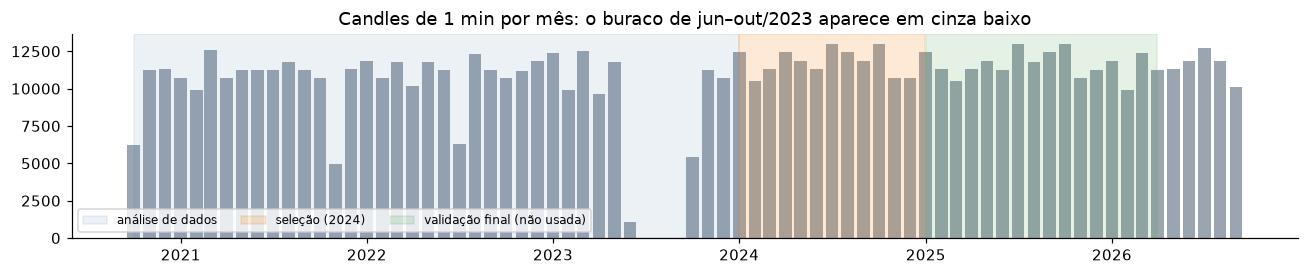

In [3]:
m1 = pd.read_csv(ARQ_WIN, sep="\t")
m1.columns = [c.strip("<>").lower() for c in m1.columns]
m1["dt"] = pd.to_datetime(m1["date"] + " " + m1["time"], format="%Y.%m.%d %H:%M:%S")
m1 = m1.drop(columns=["date", "time", "spread"]).set_index("dt").sort_index()
m1 = m1[~m1.index.duplicated()]
m1 = m1.between_time("09:00", "18:24")          # só o pregão regular

print(f"{len(m1):,} candles de 1 min · {m1.index.min()} -> {m1.index.max()} · "
      f"{m1.index.normalize().nunique()} pregões")

cob = m1.groupby(m1.index.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.bar(cob.index.to_timestamp(), cob.values, width=25, color="#9aa5b1")
ax.axvspan(pd.Timestamp("2020-10-01"), pd.Timestamp(FIM_EXPLORACAO), color="#4C78A8", alpha=0.10, label="análise de dados")
ax.axvspan(pd.Timestamp(f"{ANO_SELECAO}-01-01"), pd.Timestamp(f"{ANO_SELECAO}-12-31"), color="#F58518", alpha=0.18, label="seleção (2024)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31"), color="#54A24B", alpha=0.15, label="validação final (não usada)")
ax.set_title("Candles de 1 min por mês: o buraco de jun–out/2023 aparece em cinza baixo")
ax.legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## 2. Montar as bases de cada candle

- Cada candle de *k* minutos é formado **dentro do pregão**, alinhado ao relógio (9:00, 9:30, ...).
- **Alvo:** retorno do próximo candle do mesmo pregão. O último candle do dia fica sem alvo, para o par não atravessar a noite.
- **Features (só até t):**
  - `ret_0..2`: retorno do candle atual e dos dois anteriores; valem 0 no começo do dia, para não usar o gap de abertura.
  - `vol_20`: desvio dos últimos 20 retornos intradiários.
  - `hora`: horário do candle em horas decimais.
- `pts_prox` $= C_{t+1} - C_t$, em pontos, usado nas contas de custo.

In [4]:
def agrega_candles(m1, minutos):
    if minutos == 1:
        return m1.copy()
    regras = {"open": "first", "high": "max", "low": "min", "close": "last", "tickvol": "sum", "vol": "sum"}
    out = m1.resample(f"{minutos}min", label="left", closed="left").agg(regras)
    return out.dropna(subset=["close"])


def monta_base(m1, minutos):
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    ret = 100 * np.log(df["close"]).groupby(dia).diff()      # NaN no 1º candle do dia

    df["tem_ret_0"] = ret.notna()                             # usado no ρ₁ (exclui o 1º candle)
    df["ret_0"] = ret
    df["ret_1"] = ret.groupby(dia).shift(1)
    df["ret_2"] = ret.groupby(dia).shift(2)
    df["vol_20"] = ret.rolling(20, min_periods=10).std()
    df["hora"] = df.index.hour + df.index.minute / 60
    df["alvo"] = ret.groupby(dia).shift(-1)
    df["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]
    df[["ret_0", "ret_1", "ret_2"]] = df[["ret_0", "ret_1", "ret_2"]].fillna(0.0)
    return df.dropna(subset=["alvo", "vol_20"])


bases = {k: monta_base(m1, k) for k in CANDLES}
for k, b in bases.items():
    print(f"{k:>3} min: {len(b):>8,} linhas · {b.index.min().date()} -> {b.index.max().date()}")

  1 min:  756,333 linhas · 2020-10-15 -> 2026-09-25
  5 min:  150,285 linhas · 2020-10-15 -> 2026-09-25
 15 min:   49,642 linhas · 2020-10-15 -> 2026-09-25
 30 min:   24,135 linhas · 2020-10-15 -> 2026-09-25
 60 min:   11,865 linhas · 2020-10-16 -> 2026-09-25


## 3. Análise de dados (até 31/12/2023, sem modelo)

### 3.1 Tamanho do movimento contra o custo

Para uma previsão com correlação ρ com a variação seguinte, operar o sinal da previsão rende, em média, cerca de $\rho \cdot \sigma_{pts} \cdot \sqrt{2/\pi}$ pontos por operação (aproximação normal). Daí sai a **correlação necessária para pagar o custo**:

$$\rho_{necessário} = \frac{\text{custo}}{\sigma_{pts} \cdot 0{,}798}$$

Candles maiores andam mais, então o custo pesa menos e o ρ necessário cai. Em compensação, há menos amostras.

In [5]:
def explo(b):
    return b[b.index <= FIM_EXPLORACAO]

linhas = []
for k, b in bases.items():
    e = explo(b)
    sig_pts = e["pts_prox"].std()
    linha = {
        "candle_min": k,
        "linhas_ate_2023": len(e),
        "candles_por_dia": e.groupby(e.index.normalize()).size().median(),
        "desvio_ret_%": e["alvo"].std(),
        "desvio_pts": sig_pts,
        "mov_medio_abs_pts": e["pts_prox"].abs().mean(),
        "custo5_sobre_mov_%": 100 * CUSTO_PTS / e["pts_prox"].abs().mean(),
    }
    for c in [CUSTO_PTS]:
        linha[f"rho_nec_{c:g}pts"] = c / (sig_pts * np.sqrt(2 / np.pi))
    linhas.append(linha)

tab_mov = pd.DataFrame(linhas).set_index("candle_min")
tab_mov.style.format({
    "linhas_ate_2023": "{:,.0f}", "candles_por_dia": "{:.0f}", "desvio_ret_%": "{:.4f}",
    "desvio_pts": "{:.1f}", "mov_medio_abs_pts": "{:.1f}", "custo5_sobre_mov_%": "{:.1f}%",
    "rho_nec_5pts": "{:.3f}",
})

,linhas_ate_2023,candles_por_dia,desvio_ret_%,desvio_pts,mov_medio_abs_pts,custo5_sobre_mov_%,rho_nec_5pts
candle_min,,,,,,,
1,"371,487",534,0.0522,58.5,40.7,12.3%,0.107
5,"73,778",106,0.1147,128.6,91.7,5.5%,0.049
15,"24,364",35,0.1961,219.8,156.7,3.2%,0.029
30,"11,837",17,0.2791,312.7,223.7,2.2%,0.020
60,"5,715",8,0.3932,440.8,317.6,1.6%,0.014


### 3.2 Memória de um candle para o próximo (ρ₁)

ρ₁ = correlação entre o retorno do candle atual e o do seguinte, no mesmo pregão (sem o 1º candle do dia).

Dois erros-padrão:
- **simples**, $1/\sqrt{n}$;
- **robusto**, que considera que a volatilidade vem em grupos. Com $z$ = retornos padronizados, $\hat\rho = \overline{z_t z_{t+1}}$ e $EP = \text{desvio}(z_t z_{t+1})/\sqrt{n}$.

Se ρ₁ ficar dentro da faixa robusta, não há memória utilizável **na forma linear**. O RF ainda pode achar relações não lineares ou condicionais.

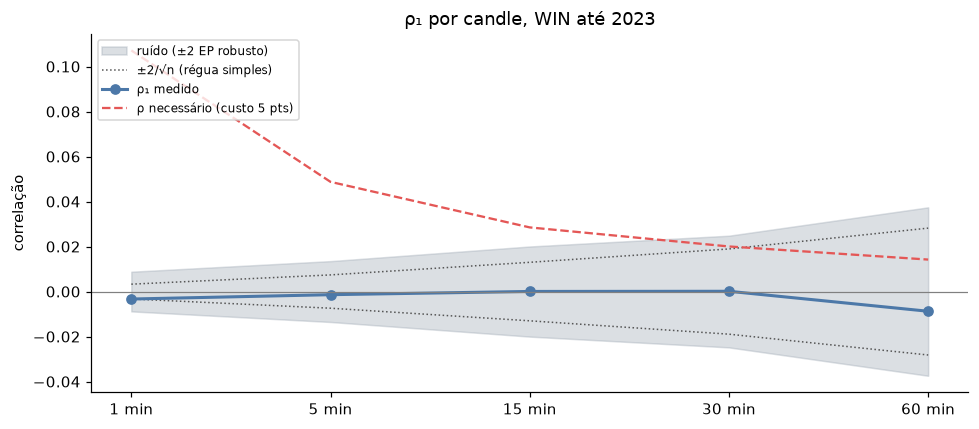

,n,rho1,ep_robusto,ep_simples,t_robusto,rho_nec_5pts
candle_min,,,,,,
1,370805,-0.0033,0.0044,0.0016,-0.7539,0.1072
5,73096,-0.0014,0.0068,0.0037,-0.2053,0.0487
15,23682,0.0000,0.0100,0.0065,0.0048,0.0285
30,11155,0.0001,0.0124,0.0095,0.0100,0.0200
60,5034,-0.0088,0.0187,0.0141,-0.4678,0.0142


In [6]:
def rho_robusto(x, y):
    zx = (x - x.mean()) / x.std()
    zy = (y - y.mean()) / y.std()
    prod = zx * zy
    n = len(prod)
    return prod.mean(), prod.std(ddof=1) / np.sqrt(n), 1 / np.sqrt(n), n

linhas = []
for k, b in bases.items():
    e = explo(b)
    e = e[e["tem_ret_0"]]
    rho, ep_rob, ep_simp, n = rho_robusto(e["ret_0"].values, e["alvo"].values)
    linhas.append({"candle_min": k, "n": n, "rho1": rho, "ep_robusto": ep_rob, "ep_simples": ep_simp,
                   "t_robusto": rho / ep_rob, "rho_nec_5pts": tab_mov.loc[k, "rho_nec_5pts"]})
tab_rho1 = pd.DataFrame(linhas).set_index("candle_min")

x = np.arange(len(CANDLES))
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(x, -2 * tab_rho1["ep_robusto"], 2 * tab_rho1["ep_robusto"], color="#9aa5b1", alpha=0.35, label="ruído (±2 EP robusto)")
ax.plot(x, 2 * tab_rho1["ep_simples"], ls=":", color="#555", lw=1, label="±2/√n (régua simples)")
ax.plot(x, -2 * tab_rho1["ep_simples"], ls=":", color="#555", lw=1)
ax.plot(x, tab_rho1["rho1"], "o-", color="#4C78A8", lw=2, label="ρ₁ medido")
ax.plot(x, tab_rho1["rho_nec_5pts"], "--", color="#E45756", label="ρ necessário (custo 5 pts)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [f"{k} min" for k in CANDLES])
ax.set_ylabel("correlação")
ax.set_title("ρ₁ por candle, WIN até 2023")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
tab_rho1.round(4)

### 3.3 Informação das features básicas, por candle

Duas medidas de quanto cada feature diz sobre o alvo, até 2023:
- **Spearman:** relação monotônica, com sinal;
- **informação mútua:** qualquer relação, inclusive não linear. Zero significa nenhuma informação. Calculada numa amostra de até 50 mil linhas.

As features de volatilidade costumam ter Spearman perto de zero e informação mútua positiva. Elas informam o **tamanho** do próximo movimento, não a direção.

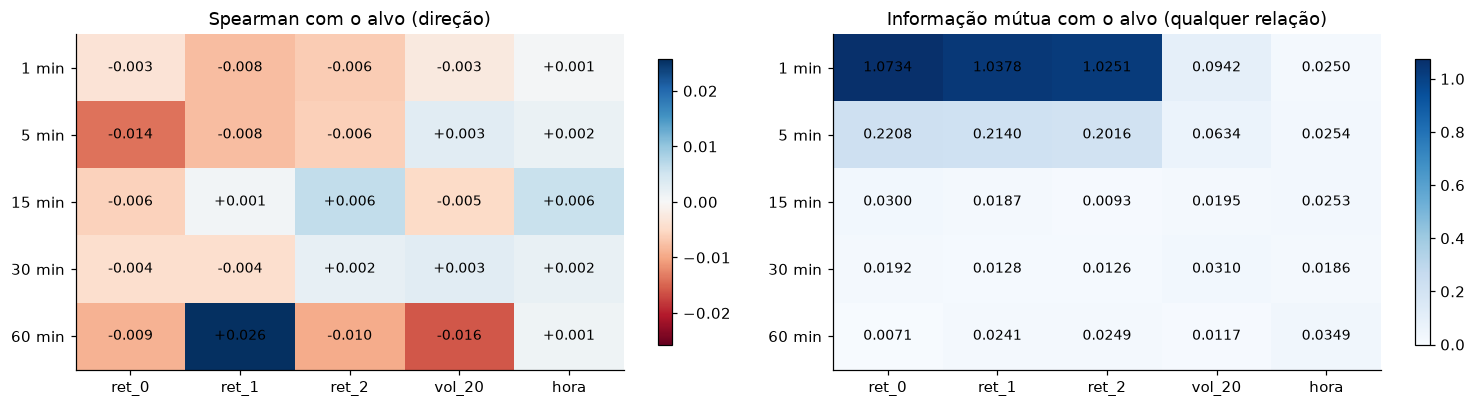

In [7]:
rng = np.random.default_rng(SEED)
sp, mi = {}, {}
for k, b in bases.items():
    e = explo(b)
    sp[k] = {f: spearmanr(e[f], e["alvo"])[0] for f in FEATURES}
    amostra = e.iloc[rng.choice(len(e), size=min(50_000, len(e)), replace=False)]
    mi[k] = dict(zip(FEATURES, mutual_info_regression(amostra[FEATURES], amostra["alvo"], random_state=SEED)))

tab_sp = pd.DataFrame(sp).T.rename_axis("candle_min")
tab_mi = pd.DataFrame(mi).T.rename_axis("candle_min")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, tab, titulo, cmap, centro in [(axes[0], tab_sp, "Spearman com o alvo (direção)", "RdBu", 0),
                                      (axes[1], tab_mi, "Informação mútua com o alvo (qualquer relação)", "Blues", None)]:
    v = tab.values
    if centro is None:
        im = ax.imshow(v, cmap=cmap, vmin=0, vmax=np.nanmax(v), aspect="auto")
    else:
        a = np.nanmax(np.abs(v)); im = ax.imshow(v, cmap=cmap, vmin=-a, vmax=a, aspect="auto")
    ax.set_xticks(range(v.shape[1]), tab.columns); ax.set_yticks(range(v.shape[0]), [f"{k} min" for k in tab.index])
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v[i, j]:+.3f}" if centro is not None else f"{v[i, j]:.4f}", ha="center", va="center", fontsize=9)
    ax.set_title(titulo); plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout(); plt.show()

## 4. Modelo: RF fixo em cada candle, seleção em 2024

Para cada candle e cada trimestre de 2024: treinar com os 12 meses anteriores, prever o trimestre e empilhar as previsões do ano.

**Métricas**

| Métrica | Leitura |
|---|---|
| Theil U | RMSE do modelo ÷ RMSE de prever zero; ≤ 1,001 passa no filtro |
| Spearman | ordenação da previsão contra o retorno real (critério principal) |
| t robusto | média dos 12 Spearman mensais ÷ (desvio entre meses / √12); não se ilude com o n grande do 1 min |
| meses ρ > 0 | quantos dos 12 meses tiveram correlação positiva |
| acerto de direção | % de sinais certos |
| desvio prev / real | quanto o RF "se arrisca": perto de 0 = previsão colada em zero |
| pts brutos/op | ganho médio operando o sinal de $\hat r$ em **todo** candle, antes do custo |
| folga sobre custo | pts brutos − 5; precisa ser positivo para a regra da etapa 5 ter chance |

In [8]:
TRIMESTRES = pd.period_range(f"{ANO_SELECAO}Q1", f"{ANO_SELECAO}Q4", freq="Q")


def theil_u(y, p):
    return np.sqrt(np.sum((y - p) ** 2) / np.sum(y ** 2))


def walk_forward(base, meses):
    prevs, n_treinos = [], []
    for q in TRIMESTRES:
        ini, fim = q.start_time, q.end_time
        tr = base[(base.index >= ini - pd.DateOffset(months=meses)) & (base.index < ini)]
        te = base[(base.index >= ini) & (base.index <= fim)]
        rf = RandomForestRegressor(**RF_PARAMS).fit(tr[FEATURES], tr["alvo"])
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[FEATURES]),
                                   "pts_prox": te["pts_prox"]}, index=te.index))
        n_treinos.append(len(tr))
    return pd.concat(prevs), min(n_treinos)


def painel(prev, k, meses, n_treino_min):
    y, p, pts = prev["alvo"].values, prev["prev"].values, prev["pts_prox"].values
    mensal = prev.groupby(prev.index.to_period("M")).apply(lambda d: spearmanr(d["prev"], d["alvo"])[0])
    mov = y != 0
    sinal = np.sign(p)
    bruto = sinal[sinal != 0] * pts[sinal != 0]
    return {
        "candle_min": k, "janela_m": meses, "n_treino_min": n_treino_min, "n": len(y),
        "theil_u": theil_u(y, p),
        "spearman": spearmanr(p, y)[0],
        "spearman_mensal_medio": mensal.mean(),
        "spearman_mensal_desvio": mensal.std(ddof=1),
        "t_robusto": mensal.mean() / (mensal.std(ddof=1) / np.sqrt(len(mensal))),
        "meses_rho_pos": int((mensal > 0).sum()),
        "acerto_dir": np.mean(np.sign(p[mov]) == np.sign(y[mov])),
        "desvio_prev_sobre_real": p.std() / y.std(),
        "pts_brutos_op": bruto.mean(),
        "ep_pts": bruto.std(ddof=1) / np.sqrt(len(bruto)),
        "folga_sobre_custo": bruto.mean() - CUSTO_PTS,
    }, mensal


resultados, mensais, previsoes = [], {}, {}
t0 = time.time()
for k in CANDLES:
    t1 = time.time()
    prev, ntr = walk_forward(bases[k], JANELA_MESES)
    linha, mensal = painel(prev, k, JANELA_MESES, ntr)
    resultados.append(linha); mensais[k] = mensal; previsoes[k] = prev
    print(f"{k:>3} min · U={linha['theil_u']:.5f}  ρ={linha['spearman']:+.4f}  t_rob={linha['t_robusto']:+.2f}  "
          f"meses ρ>0={linha['meses_rho_pos']}/12  bruto={linha['pts_brutos_op']:+.2f} pts  ({time.time() - t1:.0f}s)")
res = pd.DataFrame(resultados).set_index("candle_min")
print(f"Total: {time.time() - t0:.0f}s")

  1 min · U=1.00003  ρ=+0.0163  t_rob=+4.93  meses ρ>0=12/12  bruto=+0.37 pts  (9s)


  5 min · U=1.00054  ρ=+0.0049  t_rob=+0.32  meses ρ>0=7/12  bruto=+0.22 pts  (2s)


 15 min · U=1.00248  ρ=+0.0046  t_rob=-0.31  meses ρ>0=5/12  bruto=-0.73 pts  (2s)


 30 min · U=1.00507  ρ=+0.0005  t_rob=-0.23  meses ρ>0=5/12  bruto=-2.06 pts  (2s)


 60 min · U=1.01318  ρ=-0.0202  t_rob=-0.48  meses ρ>0=4/12  bruto=+0.16 pts  (1s)
Total: 16s


In [9]:
res.style.format({
    "n_treino_min": "{:,}", "n": "{:,}", "theil_u": "{:.5f}", "spearman": "{:+.4f}",
    "spearman_mensal_medio": "{:+.4f}", "spearman_mensal_desvio": "{:.4f}", "t_robusto": "{:+.2f}",
    "acerto_dir": "{:.1%}", "desvio_prev_sobre_real": "{:.3f}", "pts_brutos_op": "{:+.2f}",
    "ep_pts": "{:.2f}", "folga_sobre_custo": "{:+.2f}",
}).background_gradient(subset=["spearman"], cmap="RdBu", vmin=-0.03, vmax=0.03)

,janela_m,n_treino_min,n,theil_u,spearman,spearman_mensal_medio,spearman_mensal_desvio,t_robusto,meses_rho_pos,acerto_dir,desvio_prev_sobre_real,pts_brutos_op,ep_pts,folga_sobre_custo
candle_min,,,,,,,,,,,,,,
1,12,"83,902","141,302",1.00003,+0.0163,+0.0176,0.0123,+4.93,12,50.9%,0.023,+0.37,0.11,-4.63
5,12,"16,663","28,063",1.00054,+0.0049,+0.0022,0.0240,+0.32,7,50.1%,0.036,+0.22,0.55,-4.78
15,12,"5,504","9,271",1.00248,+0.0046,-0.0034,0.0382,-0.31,5,50.4%,0.061,-0.73,1.64,-5.73
30,12,"2,676","4,510",1.00507,+0.0005,-0.0039,0.0592,-0.23,5,50.6%,0.074,-2.06,3.30,-7.06
60,12,"1,311","2,255",1.01318,-0.0202,-0.0111,0.0796,-0.48,4,49.9%,0.112,+0.16,6.20,-4.84


### 4.1 Correlação obtida × correlação necessária

O ponto é o Spearman de 2024, com barra de ±2 erros-padrão robustos (entre meses). A linha tracejada é o ρ necessário para pagar 5 pts. Um candle útil precisa ter o ponto acima de zero com folga **e** perto da linha.

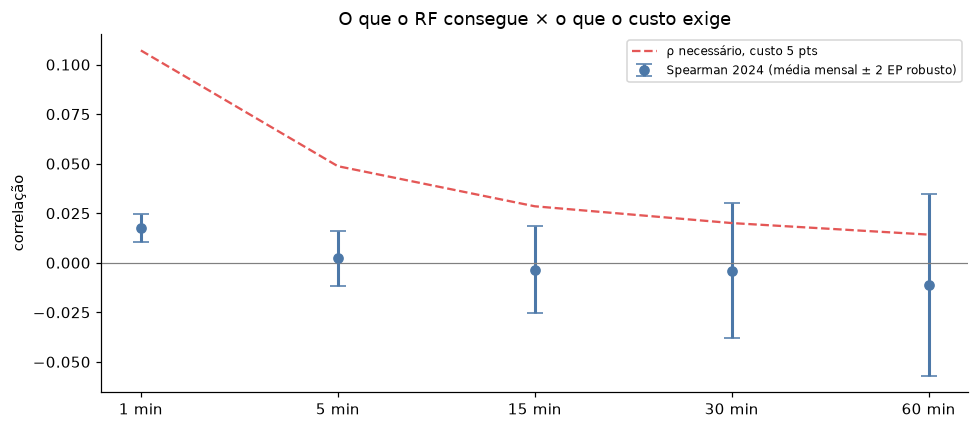

In [10]:
ep_rob = res["spearman_mensal_desvio"] / np.sqrt(12)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(x, res["spearman_mensal_medio"], yerr=2 * ep_rob, fmt="o", color="#4C78A8", capsize=5, lw=2,
            label="Spearman 2024 (média mensal ± 2 EP robusto)")
ax.plot(x, tab_mov["rho_nec_5pts"], "--", color="#E45756", label="ρ necessário, custo 5 pts")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [f"{k} min" for k in CANDLES]); ax.set_ylabel("correlação")
ax.set_title("O que o RF consegue × o que o custo exige")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4.2 Estabilidade mês a mês em 2024

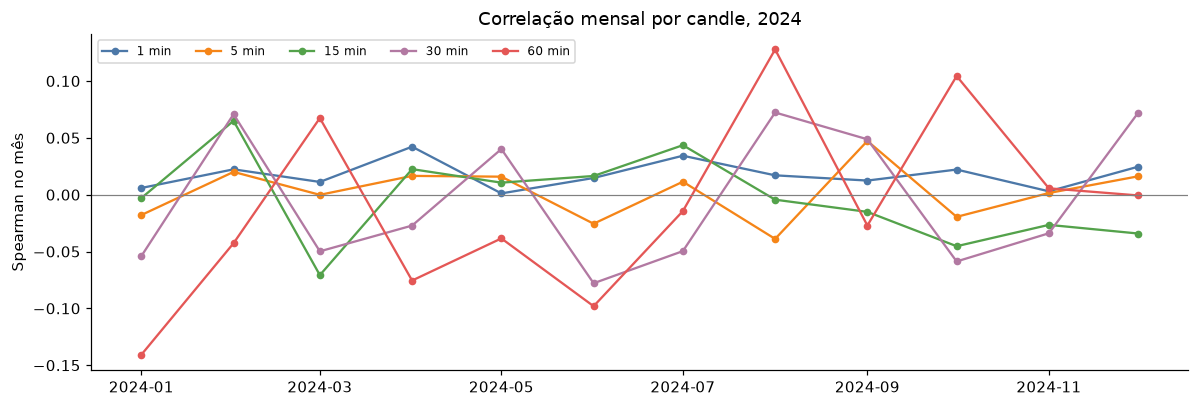

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for k in CANDLES:
    s = mensais[k]
    ax.plot(s.index.to_timestamp(), s.values, "o-", ms=4, color=CORES[k], label=f"{k} min")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Spearman no mês"); ax.set_title("Correlação mensal por candle, 2024")
ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

### 4.3 Variação seguinte por decil da previsão

Se a previsão tem sentido, as barras sobem do decil 1 (previsão mais negativa) para o 10 (mais positiva). As linhas vermelhas marcam ±5 pts: para operar com lucro, os decis extremos precisam passar delas.

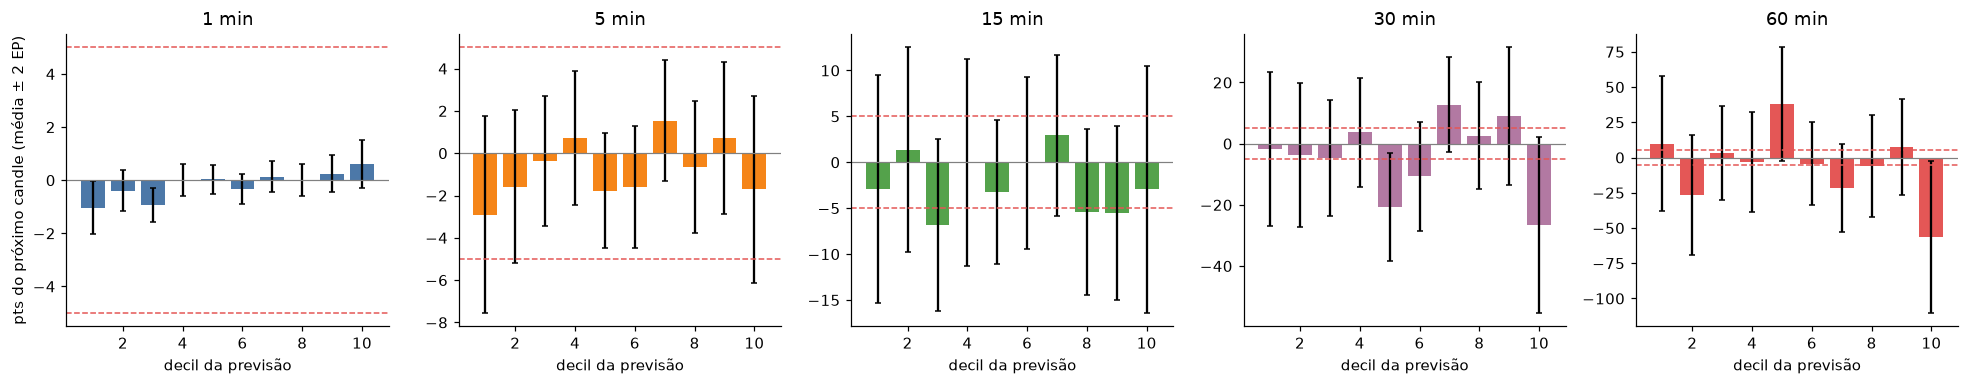

In [12]:
fig, axes = plt.subplots(1, len(CANDLES), figsize=(18, 3.6))
for ax, k in zip(axes, CANDLES):
    p = previsoes[k].copy()
    p["decil"] = pd.qcut(p["prev"].rank(method="first"), 10, labels=range(1, 11))
    g = p.groupby("decil", observed=True)["pts_prox"]
    media, ep = g.mean(), g.std(ddof=1) / np.sqrt(g.size())
    ax.bar(media.index.astype(int), media.values, yerr=2 * ep.values, color=CORES[k], capsize=2)
    ax.axhline(0, color="grey", lw=0.8)
    for c in (CUSTO_PTS, -CUSTO_PTS):
        ax.axhline(c, color="#E45756", ls="--", lw=1)
    ax.set_title(f"{k} min"); ax.set_xlabel("decil da previsão")
axes[0].set_ylabel("pts do próximo candle (média ± 2 EP)")
plt.tight_layout(); plt.show()

## 5. Robustez: o ranking muda com outra janela?

A janela é decidida no passo 3. Aqui só se confere se a escolha do candle depende da janela de 12 meses. As janelas de 6 e 24 meses pegam o buraco de jul–set/2023 (ver `n_treino_min`).

In [13]:
if RODAR_ROBUSTEZ:
    rob = [res.reset_index()[["candle_min", "janela_m", "spearman", "t_robusto", "theil_u"]]]
    for meses in JANELAS_ROBUSTEZ:
        for k in CANDLES:
            t1 = time.time()
            prev, ntr = walk_forward(bases[k], meses)
            linha, _ = painel(prev, k, meses, ntr)
            rob.append(pd.DataFrame([{c: linha[c] for c in ["candle_min", "janela_m", "spearman", "t_robusto", "theil_u"]}]))
            print(f"{k:>3} min × {meses:>2} m · ρ={linha['spearman']:+.4f}  t_rob={linha['t_robusto']:+.2f}  ({time.time() - t1:.0f}s)")
    rob = pd.concat(rob, ignore_index=True)
    tab_rob = rob.pivot(index="candle_min", columns="janela_m", values="spearman")
    tab_rank = tab_rob.rank(ascending=False).astype(int)
    print("\nSpearman 2024 por candle × janela:")
    display(tab_rob.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.03, vmax=0.03, axis=None))
    print("Posição do candle no ranking de cada janela (1 = melhor):")
    display(tab_rank)
else:
    rob = None
    print("Checagem de robustez desligada (RODAR_ROBUSTEZ = False).")

  1 min ×  6 m · ρ=+0.0120  t_rob=+3.59  (6s)


  5 min ×  6 m · ρ=+0.0136  t_rob=+1.99  (2s)


 15 min ×  6 m · ρ=-0.0051  t_rob=-0.66  (1s)


 30 min ×  6 m · ρ=+0.0150  t_rob=+0.80  (1s)


 60 min ×  6 m · ρ=-0.0092  t_rob=+0.13  (1s)


  1 min × 24 m · ρ=+0.0057  t_rob=+1.28  (28s)


... (3 outputs left out)

 60 min × 24 m · ρ=-0.0198  t_rob=-0.71  (1s)

Spearman 2024 por candle × janela:


janela_m,6,12,24
candle_min,,,
1,+0.0120,+0.0163,+0.0057
5,+0.0136,+0.0049,+0.0117
15,-0.0051,+0.0046,-0.0185
30,+0.0150,+0.0005,+0.0073
60,-0.0092,-0.0202,-0.0198


Posição do candle no ranking de cada janela (1 = melhor):


janela_m,6,12,24
candle_min,,,
1,3,1,3
5,2,2,1
15,4,3,4
30,1,4,2
60,5,5,5


## 6. Decisão

In [14]:
dec = res.copy()
dec["passa_theil"] = dec["theil_u"] <= TOL_THEIL
dec["sinal_significativo"] = (dec["t_robusto"] > 2) & (dec["spearman"] > 0)

candidatos = dec[dec["passa_theil"] & dec["sinal_significativo"]]
if len(candidatos):
    escolhido = candidatos.sort_values(["spearman", "spearman_mensal_desvio", "folga_sobre_custo"],
                                       ascending=[False, True, False]).index[0]
    situacao = "sinal significativo"
else:
    base_esc = dec[dec["passa_theil"]] if dec["passa_theil"].any() else dec
    escolhido = base_esc["spearman"].idxmax()
    situacao = "SEM sinal significativo (t robusto ≤ 2 em todos os candles)"

e = dec.loc[escolhido]
print(dec[["theil_u", "passa_theil", "spearman", "t_robusto", "meses_rho_pos", "sinal_significativo",
           "pts_brutos_op", "folga_sobre_custo"]].round(4).to_string())
print(f"\nCandle escolhido: {escolhido} min  ·  {situacao}")
print(f"  Theil U = {e['theil_u']:.5f} · Spearman = {e['spearman']:+.4f} · t robusto = {e['t_robusto']:+.2f} · "
      f"meses com ρ > 0 = {e['meses_rho_pos']}/12")
print(f"  Ganho bruto operando todo candle = {e['pts_brutos_op']:+.2f} ± {e['ep_pts']:.2f} pts "
      f"(ρ necessário p/ 5 pts = {tab_mov.loc[escolhido, 'rho_nec_5pts']:.3f})")

escolha = {"candle_min": int(escolhido), "situacao": situacao, "janela_m_usada": JANELA_MESES,
           "features": FEATURES, "rf_params": {k: v for k, v in RF_PARAMS.items() if k != "n_jobs"}}
(PASTA_RES / "passo1_escolha.json").write_text(json.dumps(escolha, indent=2, ensure_ascii=False))
tab_mov.to_csv(PASTA_RES / "passo1_movimento_custo.csv")
tab_rho1.to_csv(PASTA_RES / "passo1_rho1.csv")
res.to_csv(PASTA_RES / "passo1_modelo_2024.csv")
if rob is not None:
    rob.to_csv(PASTA_RES / "passo1_robustez_janelas.csv", index=False)
print(f"\nSalvo em {PASTA_RES}")

            theil_u  passa_theil  spearman  t_robusto  meses_rho_pos  sinal_significativo  pts_brutos_op  folga_sobre_custo
candle_min                                                                                                                 
1            1.0000         True    0.0163     4.9336             12                 True         0.3652            -4.6348
5            1.0005         True    0.0049     0.3212              7                False         0.2218            -4.7782
15           1.0025        False    0.0046    -0.3124              5                False        -0.7308            -5.7308
30           1.0051        False    0.0005    -0.2307              5                False        -2.0554            -7.0554
60           1.0132        False   -0.0202    -0.4810              4                False         0.1619            -4.8381

Candle escolhido: 1 min  ·  sinal significativo
  Theil U = 1.00003 · Spearman = +0.0163 · t robusto = +4.93 · meses com ρ > 0 = 12

## 7. Como ler e próximos passos

**Leitura do resultado**
- **Análise de dados (3.1 e 3.2):** se ρ₁ ficar dentro da faixa robusta em todos os candles e muito abaixo do ρ necessário, não há memória linear que pague o custo. Qualquer ganho do RF terá de vir de relações não lineares ou condicionais.
- **Modelo (4):** o candle escolhido é só o **melhor ponto de partida**. Um t robusto > 2 com ganho bruto bem abaixo do custo quer dizer que há sinal estatístico, mas não econômico, ainda.
- **Robustez (5):** se o candle escolhido muda de posição entre as janelas, a escolha é frágil. Vale confirmá-la no passo 6.

**Próximos passos do plano**
1. **Passo 2 — Features:** no candle escolhido, gerar ~15 candidatas e escolher 5–10 por Spearman, informação mútua, decis, estabilidade anual e importância por permutação.
2. **Passo 3 — Janela e retreino:** curva de envelhecimento do modelo e walk-forward com 3/6/12/24 meses × retreino mensal/trimestral/semestral.
3. **Passo 4 — Hiperparâmetros:** curva de nº de árvores e grade pequena de profundidade × % por folha × `max_features`.
4. **Passo 5 — Regras de compra e venda:** limiar pelos decis, lado, saída (TP/stop por volatilidade) e filtros de horário.
5. **Passo 6 — Confirmação, congelamento e validação** em 01/2025 → 03/2026.

**Limitações deste passo**
- Seleção feita só em 2024; repetir em 2023 aumentaria a confiança.
- O ρ necessário usa a aproximação normal; retornos têm caudas pesadas, então é uma ordem de grandeza.
- Features e hiperparâmetros básicos podem favorecer alguns candles; a confirmação do passo 6 cobre isso.